# Robustness of the inference to sparse data

First, we need to observe how the downsmapling process is different from the backtracked distribution.

In [2]:
display("text/html", "<style>.container { width:100% !important; }</style>")

In [252]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM, StatsBase, Distributions

In [4]:
Plots.theme(:dao)

In [5]:
include("/home/jamesh/GitHub/Ecological-Preferential-Attachment/diversity-simulator.jl")
using .dsim

In [6]:
pal = cgrad(:tol_muted);
cpal = [pal[i] for i in 0.0:1/5:1]

In [7]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
read_data = filter(:nreads => !=(0), read_data)
# first split on classification
gd1 = groupby(read_data, :classification);

gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

classes = [gd_classes[i][1][!,:classification][2] for i in 1:length(gd_classes)]
classes = strip.(lowercase.(classes))
classes[10] = "marine hydrothermal vents"
classes[6] = "oral cavity"
classes[5] = "terrestrial soil"
classes[end] = "activated sludge"
classes;

Now need to pick an initial condition.

In [8]:
ind_choice = 2;
data = gd_classes[ind_choice];
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
small_to_large = sortperm(sizes);
ic_sys = sort(data[small_to_large[1]][!,:count],rev=true);

In [267]:
ic_sys;

# First make the big system and the small system.

## $\gamma=1$

In [233]:
small_sys = dsim.create_cell(0.42, 1, 3, 10^5, ic_sys, :pdf)
big_sys = dsim.create_cell(0.42, 1, 3, 10^6, small_sys, :pdf);

Now make the downsampled system.

In [234]:
probs = big_sys ./sum(big_sys);

In [235]:
function sample_counts(p::Vector{Float64}, N::Int)
    M = length(p)
    counts = zeros(Int, M)

    w = Weights(p)

    samples = sample(1:M, w, N)  # draw N samples at once

    for i in samples
        counts[i] += 1
    end
    
    sort!(counts, rev=true)
    counts = counts[counts .!=0]
    
    return counts
end

sample_counts (generic function with 1 method)

In [236]:
ds_sys = sample_counts(probs, 10^5);

In [237]:
sum(small_sys)

100000.0

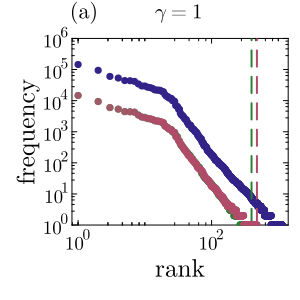

In [238]:
s1 = scatter(big_sys, label = L"full system, $N=10^6$", c = cpal[1])

scatter!(small_sys, label = L"back-tracked, $N=10^5$", c = cpal[3], alpha = 0.8)
plot!([length(small_sys),length(small_sys)], [0.1,10^7], ylims = [1,10^6], label = :none, c = cpal[3], linestyle = :dash, lw = 2)

scatter!(ds_sys, label = L"down-sampled, $N=10^5$", c = cpal[end-1], alpha = 0.8)
plot!([length(ds_sys),length(ds_sys)], [0.1,10^7], label = :none, c = cpal[end-1], linestyle = :dash, lw = 2)

scatter!(xaxis = :log10, yaxis = :log10)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :none)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = L"(a) $\quad\quad\quad\gamma=1$", titleloc = :left, xlabel = "rank", ylabel = "frequency")

## $\gamma>1$

In [239]:
small_sys2 = dsim.create_cell(0.42, 1.2, 3, 10^5, ic_sys, :pdf)
big_sys2 = dsim.create_cell(0.42, 1.2, 3, 10^6, small_sys2, :pdf);

Now make the downsampled system.

In [240]:
probs2 = big_sys2 ./sum(big_sys2);

In [241]:
ds_sys2 = sample_counts(probs2, 10^5);

In [242]:
sum(small_sys2)

100000.0

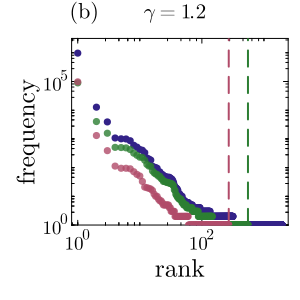

In [243]:
s2 = scatter(big_sys2, label = "full system", c = cpal[1])

scatter!(small_sys2, label = "back-tracked", c = cpal[3], alpha = 0.8)
plot!([length(small_sys2),length(small_sys2)], [0.1,10^7], ylims = [1,10^6.5], label = :none, c = cpal[3], linestyle = :dash, lw = 2)

scatter!(ds_sys2, label = "down-sampled", c = cpal[end-1], alpha = 0.8)
plot!([length(ds_sys2),length(ds_sys2)], [0.1,10^7], label = :none, c = cpal[end-1], linestyle = :dash, lw = 2)


scatter!(xaxis = :log10, yaxis = :log10)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :none)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = L"(b) $\quad\quad\;\gamma=1.2$", titleloc = :left, xlabel = "rank", ylabel = "frequency")

## $\gamma<1$

In [244]:
small_sys3 = dsim.create_cell(0.42, 0.8, 3, 10^5, ic_sys, :pdf)
big_sys3 = dsim.create_cell(0.42, 0.8, 3, 10^6, small_sys3, :pdf);

Now make the downsampled system.

In [245]:
probs3 = big_sys3 ./sum(big_sys3);

In [246]:
ds_sys3 = sample_counts(probs3, 10^5);

In [247]:
sum(small_sys3)

100000.0

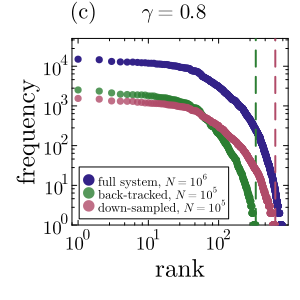

In [248]:
s3 = scatter(big_sys3, label = L"full system, $N=10^6$", c = cpal[1])

scatter!(small_sys3, label = L"back-tracked, $N=10^5$", c = cpal[3], alpha = 0.8)
plot!([length(small_sys3),length(small_sys3)], [0.1,10^5], ylims = [1,10^4.7], label = :none, c = cpal[3], linestyle = :dash, lw = 2)

scatter!(ds_sys3, label = L"down-sampled, $N=10^5$", c = cpal[end-1], alpha = 0.8)
plot!([length(ds_sys3),length(ds_sys3)], [0.1,10^5], label = :none, c = cpal[end-1], linestyle = :dash, lw = 2)

scatter!(xaxis = :log10, yaxis = :log10)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :bottomleft)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = L"(c) $\quad\quad\;\gamma=0.8$", titleloc = :left, xlabel = "rank", ylabel = "frequency")

In [249]:
using Plots.Measures

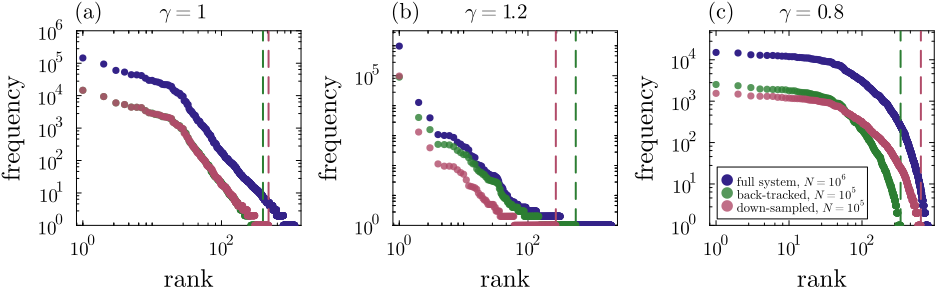

In [433]:
plot(s1,s2,s3, layout = (1,3), size = (950,300), bottom_margin = 10mm, top_margin = 3mm, left_margin = 5mm, right_margin = 2mm)
# savefig("ds_gamma_plots.pdf")

# Data-informed robustness space

The median value of $\gamma=1.06$ with many values over the range $[0.95,1.2]$, and the median value of $\theta=0.42$ with many values over the range $[-1,1]$. We will pick 20 parameter points in this regime of the space and show the parameter drift.

I need to make the data that can be imported into a `sbatch` process in the CARC cluster. 

In [258]:
# γ_rands = rand(Uniform(0.95,1.2),20)
γ_rands;

In [259]:
# θ_rands = rand(Uniform(-1,1),20)
θ_rands;

In [260]:
γθ_df = DataFrame(γ = γ_rands, θ = θ_rands);

In [261]:
# CSV.write("rand_γθ_df.csv", γθ_df)

"rand_γθ_df.csv"

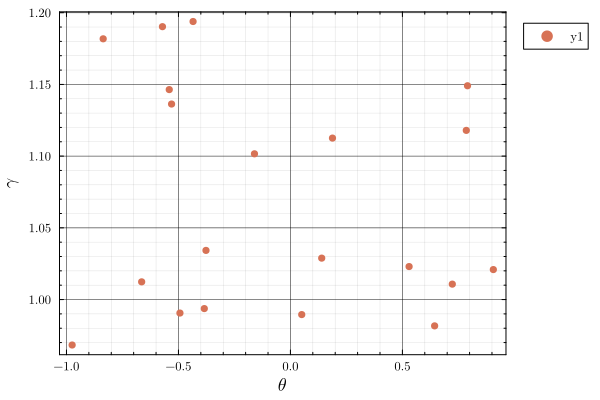

In [265]:
scatter(θ_rands, γ_rands, xlabel = L"\theta", ylabel = L"\gamma")

Now, we downsampled distributions for each parameter set which will be stored in the folder `ds_distributions`.

In [270]:
for i in 1:20
    # simulate full system size
    b_sys = dsim.create_cell(θ_rands[i], γ_rands[i], 1, 10^6, ic_sys, :pdf);
    # find probs of being in each species
    p_sys = b_sys ./sum(b_sys);
    # downsample
    d_sys = sample_counts(p_sys, 10^5);
    # save the downsample
    df_temp = DataFrame(ds_abundance = d_sys)
    CSV.write("./ds_distributions/ds_dist_$(i).csv", df_temp)
end

# Let's import the real and inferred parameters

In [273]:
real_pars = CSV.read("rand_γθ_df.csv", DataFrame)

Row,γ,θ
,Float64,Float64
1,1.11257,0.187843
2,1.03426,-0.377011
3,1.14907,0.790801
4,1.14639,-0.541046
5,1.19386,-0.434677
6,1.13632,-0.530689
7,0.98951,0.0505611
8,1.02089,0.906129
9,1.10161,-0.160506


In [274]:
inf_pars = CSV.read("inferred_ds_parameters.csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.37197,1.18026,2.17105
2,-1.42114,1.08509,2.67696
3,0.972072,1.19173,1.38946
4,0.405968,1.26533,2.10328
5,0.491432,1.29286,1.59344
6,0.325175,1.16675,2.07618
7,-0.416883,1.02064,2.4163
8,0.851565,0.99468,1.31485
9,0.313716,1.16101,1.77833


In [396]:
gamma_real = real_pars[!,:γ]
theta_real = exp.(real_pars[!,:θ])
gamma_inf = inf_pars[!,:gamma]
theta_inf = exp.(inf_pars[!,:theta]);

In [397]:
Δθ = theta_real .- theta_inf;

In [398]:
Δγ = gamma_real .- gamma_inf;

In [399]:
xs = gamma_real;
ys = Δγ;
df1 = DataFrame(y = ys, x = xs);
glm1 = lm(@formula(y ~ x), df1);
a1,b1 = coef(glm1)

2-element Vector{Float64}:
  0.4560673648642259
 -0.46622878592858147

In [400]:
r2(glm1)

0.6665606481937665

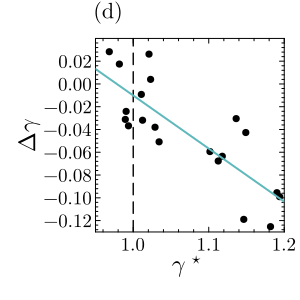

In [401]:
v1 = scatter(gamma_real, Δγ, c = :black)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(xlabel = L"\gamma^\star", ylabel = L"\Delta \gamma", legend = :none, size = (300,300), grid = false, minorgrid = false)
plot!(right_margin = 2mm)
plot!([1,1], [-10,10], xlims = [0.95,1.2], ylims = [-0.13,0.04], color = :black, linestyle = :dash)
plot!([0.8, 1.3], [a1 + b1*0.8, a1 + b1*1.3], lw = 2, c = cpal[2], xticks = [1,1.1,1.2])
plot!(title = "(d)", titleloc = :left)

In [402]:
xs = theta_real;
ys = Δγ;
df2 = DataFrame(y = ys, x = xs);
glm2 = lm(@formula(y ~ x), df2);
a2,b2 = coef(glm2)

2-element Vector{Float64}:
 -0.07384736364184775
  0.027961689365647805

In [403]:
r2(glm2)

0.19204894150495955

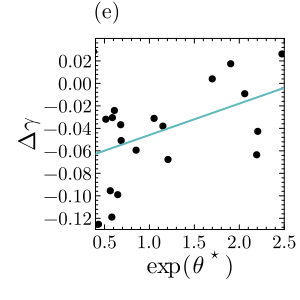

In [404]:
v2 = scatter(theta_real, Δγ, c = :black)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(xlabel = L"\exp(\theta^\star)", ylabel = L"\Delta \gamma", legend = :none, size = (300,300), grid = false, minorgrid = false)
plot!(right_margin = 2mm)
plot!([0, 3], [a2 + b2*0, a2 + b2*3], lw = 2, c = cpal[2], xlims = [0.4,2.5], ylims = [-0.13, 0.04])
plot!(title = "(e)", titleloc = :left)

In [405]:
xs = gamma_real;
ys = Δθ;
df3 = DataFrame(y = ys, x = xs);
glm3 = lm(@formula(y ~ x), df3);
a3,b3 = coef(glm3)

2-element Vector{Float64}:
  7.450351493257768
 -7.10299482599652

In [406]:
r2(glm3)

0.8580258234087448

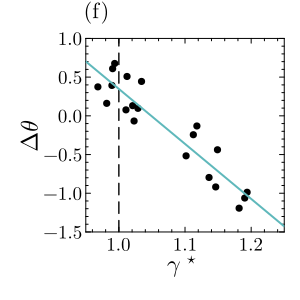

In [407]:
v3 = scatter(gamma_real, Δθ, c = :black)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(xlabel = L"\gamma^\star", ylabel = L"\Delta \theta", legend = :none, size = (300,300), grid = false, minorgrid = false)
plot!(right_margin = 2mm)
plot!([1,1], [-10,10], xlims = [0.95,1.25], ylims = [-1.5,1.0], color = :black, linestyle = :dash)
plot!([0.8, 1.3], [a3 + b3*0.8, a3 + b3*1.3], lw = 2, c = cpal[2], xticks = [1,1.1,1.2])
plot!(title = "(f)", titleloc = :left)

In [408]:
xs = theta_real;
ys = Δθ;
df4 = DataFrame(y = ys, x = xs);
glm4 = lm(@formula(y ~ x), df4);
a4,b4 = coef(glm4)

2-element Vector{Float64}:
 -0.29452906549175906
  0.1338750853150039

In [409]:
r2(glm4)

0.02441521121098722

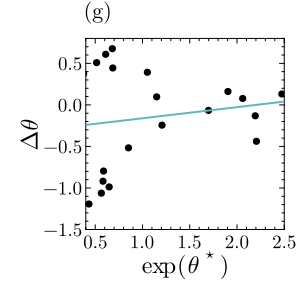

In [410]:
v4 = scatter(theta_real, Δθ, c = :black)
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(xlabel = L"\exp(\theta^\star)", ylabel = L"\Delta \theta", legend = :none, size = (300,300), grid = false, minorgrid = false)
plot!(right_margin = 2mm)
plot!([0, 3], [a4 + b4*0, a4 + b4*3], lw = 2, c = cpal[2], xlims = [0.4,2.5], ylims = [-1.5, 0.8])
plot!(title = "(g)", titleloc = :left)

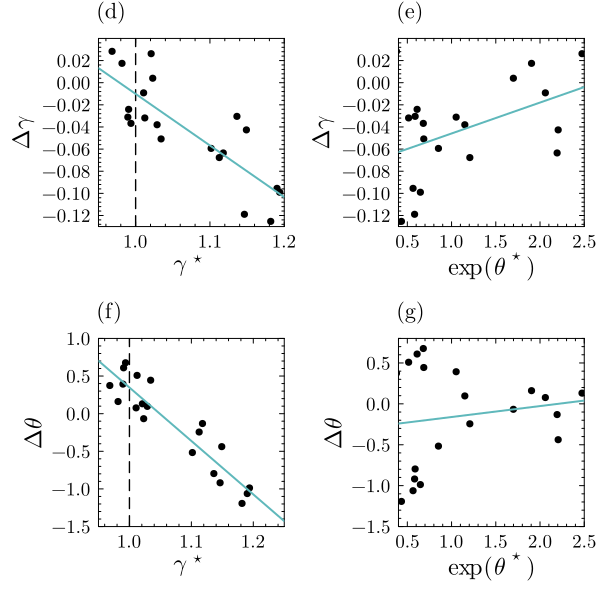

In [413]:
plot(v1,v2,v3,v4, layout = (2,2), size = (600,600))
# savefig("indiv_rob_plots.pdf")

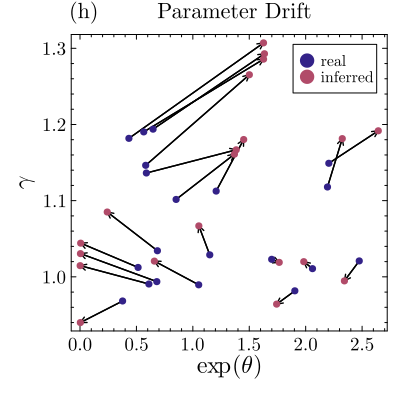

In [431]:
plot(legend = :topright, size = (400,400), grid = false, minorgrid = false)
for i in 1:20
    plot!([theta_real[i], theta_inf[i]], [gamma_real[i], gamma_inf[i]], label = :none, color = :black,arrow=true)
end
scatter!(theta_real, gamma_real, label = "real", c = cpal[1])
scatter!(theta_inf, gamma_inf, label = "inferred", c = cpal[end-1])

plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 10, xtickfontsize = 12, ytickfontsize = 12, titlefontsize = 14)
plot!(title = "(h)        Parameter Drift", titleloc = :left, xlabel = L"\exp(\theta)", ylabel = L"\gamma", top_margin = 0mm)
# savefig("parameter-drift.pdf")